In [1]:
# === Ô GHI LOG  ===
import logging, sys, datetime, warnings
from pathlib import Path
TEN_NOTEBOOK = "01_E0.4_so_dac_trung_toi_uu_Han"
NGUOI_CHAY   = "Han"

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").exists())  # thư mục gốc repo
thu_muc_log = ROOT / "logs" / "eda_log"   # log các notebook EDA để riêng
thu_muc_log.mkdir(parents=True, exist_ok=True)
file_log = thu_muc_log / f"{datetime.datetime.now():%Y-%m-%d_%H%M}_{TEN_NOTEBOOK}.log"
tep_log = open(file_log, "a", encoding="utf-8", buffering=1)

if hasattr(sys.stdout, "echo"):                  # chạy trong Jupyter / VS Code: nhờ kernel chép thêm ra file, không thay sys.stdout
    sys.stdout.echo = tep_log
    sys.stderr.echo = tep_log
else:                                            # chạy bằng python thường
    class GhiCaHai:
        def __init__(self, man_hinh, tep): self.man_hinh, self.tep = man_hinh, tep
        def write(self, s): self.man_hinh.write(s); self.tep.write(s); return len(s)
        def flush(self): self.man_hinh.flush(); self.tep.flush()
        def __getattr__(self, ten): return getattr(self.man_hinh, ten)
    sys.stdout = GhiCaHai(sys.__stdout__, tep_log)

logging.basicConfig(stream=sys.stdout, level=logging.INFO, force=True,
                    format="%(asctime)s | %(levelname)s | %(message)s", datefmt="%Y-%m-%d %H:%M:%S")
logging.captureWarnings(True)
log = logging.getLogger(TEN_NOTEBOOK)
log.info(f"Bắt đầu chạy {TEN_NOTEBOOK} – người chạy: {NGUOI_CHAY} – file log: {file_log}")

2026-11-14 18:12:58 | INFO | Bắt đầu chạy 01_E0.4_so_dac_trung_toi_uu_Han – người chạy: Han – file log: /Users/caongochan/Documents/Challenge_2_Music_Genre_Classification/logs/2026-11-14_1812_01_E0.4_so_dac_trung_toi_uu_Han.log


# E0.4 – Bao nhiêu đặc trưng là đủ? (C2 – Music Genre)

| | |
|---|---|
| **Tác giả** | Cao Ngọc Hân – Nhóm 11 |
| **Ngày tạo** | 14/11/2026 |
| **Thí nghiệm** | E0.4 – Bao nhiêu đặc trưng là đủ? |
| **Câu hỏi nghiên cứu** | RQ0: Đặc trưng âm thanh nào phân biệt các thể loại tốt nhất? |
| **Đọc vào** | `data/raw/train.csv`, `figures/eda/c2_E0.2_xep_hang_dac_trung.csv` (từ E0.2) |
| **Ghi ra** | `figures/eda/c2_E0.4_duong_cong_so_dac_trung.csv`, `c2_E0.4_sweet_spot.png`, `c2_E0.4_tom_tat.txt` |

**Lịch sử sửa**

| Ngày | Người | Nội dung |
|---|---|---|
| 08/11/2026 | Hân | Viết trong `01_eda_Han.ipynb` (E0.1–E0.6 chung một notebook) |
| 14/11/2026 | Hân | Tách thành notebook riêng; thêm ô ghi log ra `logs/` |

Notebook chỉ dùng thống kê và mô hình đơn giản (hồi quy logistic). Mô hình mạnh là việc của Nhung.

**Cách chạy:** chạy các notebook EDA theo thứ tự E0.1 → E0.6 (Run All). File log nằm ở `logs/eda_log/`. Bản gộp đọc từ trên xuống: `00_EDA_tong_hop_C2_Han.ipynb`.

In [2]:
import os, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.feature_selection import mutual_info_classif, f_classif
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid", font_scale=1.0)

SEED = 42
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").exists())  # notebook nằm ở notebooks/eda/
DATA = ROOT / "data" / "raw"
FIG = ROOT / "figures" / "eda"
FIG.mkdir(parents=True, exist_ok=True)

# W&B: USE_WANDB là công tắc chung; LOG chọn thí nghiệm nào được log ở lần chạy này.
# Các run W&B của E0.1–E0.6 đã log ngày 08/11 (từ 01_eda_Han.ipynb).
# Để USE_WANDB = False khi chạy lại để không tạo run trùng; bật True nếu cần log run mới.
USE_WANDB = False
LOG = {"E0.4": True}
WANDB_ENTITY = "sgu-mayhoc-nhom11"
WANDB_PROJECT = "challenge-2-music-genre-classification"
log.info(f"ROOT: {ROOT}")

2026-11-14 18:13:00 | INFO | ROOT: /Users/caongochan/Documents/Challenge_2_Music_Genre_Classification


In [3]:
train = pd.read_csv(DATA / "train.csv")
test = pd.read_csv(DATA / "test.csv")
TARGET, ID = "Class", "Id"
TEXT_COLS = ["Artist Name", "Track Name"]
print("train:", train.shape, "| test:", test.shape)
train.head()

train: (14396, 18) | test: (3600, 17)


,Id,Artist Name,Track Name,Popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_in min/ms,time_signature,Class
0,1,Marina Maximilian,Not Afraid,37.0,0.334,0.536,9.0,-6.649,0,0.0381,0.378000,NaN,0.106,0.235,152.429,204947.0,4,9
1,2,The Black Keys,Howlin' for You,67.0,0.725,0.747,11.0,-5.545,1,0.0876,0.027200,0.0468,0.104,0.380,132.921,191956.0,4,6
2,3,Royal & the Serpent,phuck u,NaN,0.584,0.804,7.0,-6.094,1,0.0619,0.000968,0.6350,0.284,0.635,159.953,161037.0,4,10
3,4,Detroit Blues Band,Missing You,12.0,0.515,0.308,NaN,-14.711,1,0.0312,0.907000,0.0213,0.300,0.501,172.472,298093.0,3,2
4,5,Coast Contra,My Lady,48.0,0.565,0.777,6.0,-5.096,0,0.2490,0.183000,NaN,0.211,0.619,88.311,254145.0,4,5


In [4]:
# Chuẩn bị chung (lấy lại từ E0.1, E0.2): tách đặc trưng; đổi thời lượng về phút và điền thiếu bằng trung vị
# (chỉ để phân tích, không phải pipeline mô hình); 5 fold phân tầng và hồi quy logistic dùng chung
X = train.drop(columns=[ID, TARGET])
y = train[TARGET]
num_cols = [c for c in X.columns if c not in TEXT_COLS]
Xa = X[num_cols].copy()
Xa["duration_in min/ms"] = np.where(Xa["duration_in min/ms"] < 30, Xa["duration_in min/ms"],
                                    Xa["duration_in min/ms"] / 60000)
Xa = Xa.rename(columns={"duration_in min/ms": "duration_min"})
num_cols = list(Xa.columns)
Xa = Xa.fillna(Xa.median())

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
def logit():
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced"))
baseline_f1 = 1 / y.nunique()
log.info(f"{len(num_cols)} đặc trưng số, {y.nunique()} thể loại, macro-F1 ngẫu nhiên ≈ {baseline_f1:.3f}")

2026-11-14 18:13:00 | INFO | 14 đặc trưng số, 11 thể loại, macro-F1 ngẫu nhiên ≈ 0.091


In [5]:
# Đọc xếp hạng đặc trưng từ E0.2 (chạy E0.2 trước)
scores = pd.read_csv(FIG / "c2_E0.2_xep_hang_dac_trung.csv", index_col=0)
log.info(f"Đã đọc xếp hạng E0.2: {len(scores)} đặc trưng, top 3 = {list(scores.index[:3])}")

2026-11-14 18:13:00 | INFO | Đã đọc xếp hạng E0.2: 14 đặc trưng, top 3 = ['acousticness', 'energy', 'danceability']


## E0.4 – Bao nhiêu đặc trưng là đủ?

Chọn đặc trưng tuần tự tiến (forward SFS) với hồi quy logistic (chuẩn hóa, `class_weight="balanced"`), mỗi bước thêm đặc trưng làm macro-F1 stratified 5-fold tăng nhiều nhất. So sánh với đường lấy top-k theo xếp hạng E0.2. **Sweet spot** là số đặc trưng nhỏ nhất đạt macro-F1 cách mức cao nhất không quá 0.005.

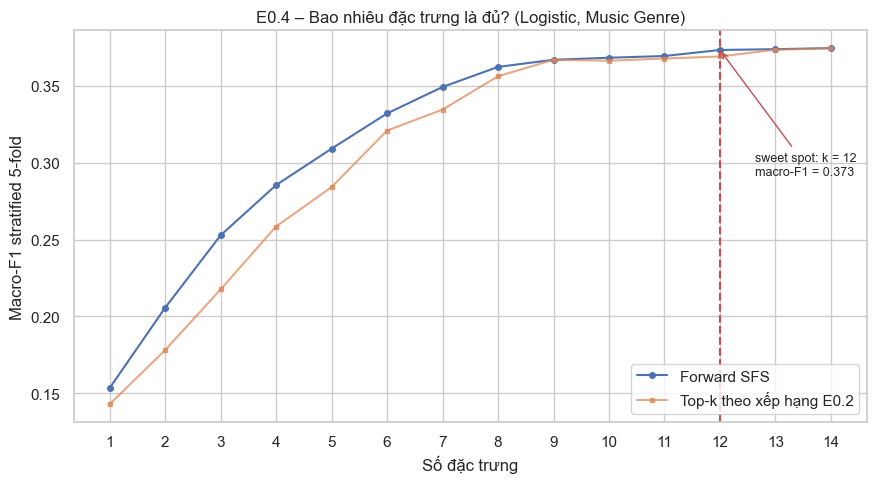

Sweet spot: 12 đặc trưng, macro-F1 = 0.373 (cao nhất 0.374)
Thứ tự SFS chọn: energy, speechiness, instrumentalness, acousticness, Popularity, valence, danceability, duration_min, loudness, time_signature, mode, liveness, key, tempo


In [6]:
def cv_f1(feats):
    return cross_val_score(logit(), Xa[feats], y, cv=skf, scoring="f1_macro", n_jobs=-1).mean()

selected, sfs_curve, remaining = [], [], list(num_cols)
while remaining:
    best = max(remaining, key=lambda f: cv_f1(selected + [f]))
    selected.append(best); remaining.remove(best)
    sfs_curve.append(cv_f1(selected))
rank_order = list(scores.index)
rank_curve = [cv_f1(rank_order[:k]) for k in range(1, len(num_cols) + 1)]

curve = pd.DataFrame({"k": range(1, len(num_cols) + 1), "dac_trung_them_vao": selected,
                      "macroF1_SFS": sfs_curve, "macroF1_top_k_E0.2": rank_curve})
best_f1 = curve["macroF1_SFS"].max()
sweet_k = int(curve.loc[curve["macroF1_SFS"] >= best_f1 - 0.005, "k"].min())
curve.to_csv(FIG / "c2_E0.4_duong_cong_so_dac_trung.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(curve["k"], curve["macroF1_SFS"], marker="o", ms=4, label="Forward SFS")
ax.plot(curve["k"], curve["macroF1_top_k_E0.2"], marker="s", ms=3, alpha=0.7, label="Top-k theo xếp hạng E0.2")
ax.axvline(sweet_k, ls="--", color="#C44E52")
ax.annotate(f"sweet spot: k = {sweet_k}\nmacro-F1 = {curve.at[sweet_k-1, 'macroF1_SFS']:.3f}",
            (sweet_k, curve.at[sweet_k-1, "macroF1_SFS"]), textcoords="offset points", xytext=(25, -90),
            fontsize=9, arrowprops=dict(arrowstyle="->", color="#C44E52"))
ax.set_xticks(curve["k"])
ax.set_xlabel("Số đặc trưng"); ax.set_ylabel("Macro-F1 stratified 5-fold")
ax.set_title("E0.4 – Bao nhiêu đặc trưng là đủ? (Logistic, Music Genre)")
ax.legend(loc="lower right"); plt.tight_layout(); plt.savefig(FIG / "c2_E0.4_sweet_spot.png", dpi=150); plt.show()
print(f"Sweet spot: {sweet_k} đặc trưng, macro-F1 = {curve.at[sweet_k-1, 'macroF1_SFS']:.3f} (cao nhất {best_f1:.3f})")
print("Thứ tự SFS chọn:", ", ".join(selected))

## Tóm tắt E0.4

In [7]:
summary = f"""E0.4 (C2): sweet spot {sweet_k} đặc trưng, macro-F1 = {curve.at[sweet_k-1, 'macroF1_SFS']:.3f} (dùng hết {len(num_cols)}: {curve['macroF1_SFS'].iloc[-1]:.3f}).
  SFS chọn: {', '.join(selected[:sweet_k])}."""
log.info("Tóm tắt E0.4:\n" + summary)
(FIG / "c2_E0.4_tom_tat.txt").write_text(summary, encoding="utf-8")

2026-11-14 18:13:16 | INFO | Tóm tắt E0.4:
E0.4 (C2): sweet spot 12 đặc trưng, macro-F1 = 0.373 (dùng hết 14: 0.374).
  SFS chọn: energy, speechiness, instrumentalness, acousticness, Popularity, valence, danceability, duration_min, loudness, time_signature, mode, liveness.


230

## Log lên W&B (minh chứng)

In [8]:
if USE_WANDB:
    import wandb
    def log_run(exp, name, metrics, tables, images, config=None):
        if not LOG.get(exp):
            print(f"Bỏ qua {exp} (LOG = False)"); return
        run = wandb.init(entity=WANDB_ENTITY, project=WANDB_PROJECT, name=name,
                         tags=[exp, "Han", "EDA"], config={"seed": SEED, **(config or {})})
        run.log({**metrics,
                 **{k: wandb.Table(dataframe=v) for k, v in tables.items()},
                 **{f.removesuffix(".png"): wandb.Image(str(FIG / f)) for f in images}})
        run.finish()

    log_run("E0.4", "c2-E0.4-Han-so-dac-trung-toi-uu",
            {"sweet_spot_k": sweet_k, "f1_sweet_spot": float(curve.at[sweet_k-1, "macroF1_SFS"]), "f1_best": float(best_f1)},
            {"duong_cong": curve.round(4)}, ["c2_E0.4_sweet_spot.png"],
            {"model": "LogisticRegression(class_weight=balanced)", "cv": "stratified 5-fold"})

## Nhật ký

- 08/11/2026 – Viết E0.4 lần đầu trong notebook `01_eda_Han.ipynb`. Commit `3f161ad`.
- 14/11/2026 – Tách E0.4 ra thành notebook riêng `01_E0.4_so_dac_trung_toi_uu_Han.ipynb`, thêm ô ghi log. Commit `eaa2795`.